## Import

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

## Questions :

- What's the most popular product ?
- What's the most popular aisle ?
- What's the least ordered product ?
- What's the most addictive product ?
- Can we predict how big a client's shopping cart will be only taking account of the first item he bought ?
- What's the most "bought in bulk" item ?
- How many client profiles can we point out ?
- How often is toilet paper bought by the same individual ?
- What item has the biggest quantity to selling ratio ?
- What item has the smallest quantity to selling ratio ?


## Data Traitment

### Import Pandas and datasets

In [21]:
aisles = pd.read_csv("aisles.csv")
departments = pd.read_csv("departments.csv")
order_products = pd.read_csv("order_products.csv")
orders = pd.read_csv("orders.csv")
products = pd.read_csv("products.csv")

### Print all datasets infos

In [22]:
aisles.info()
departments.info()
order_products.info()
orders.info()
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   aisle_id  134 non-null    int64
 1   aisle     134 non-null    str  
dtypes: int64(1), str(1)
memory usage: 2.2 KB
<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   department_id  21 non-null     int64
 1   department     21 non-null     str  
dtypes: int64(1), str(1)
memory usage: 468.0 bytes
<class 'pandas.DataFrame'>
RangeIndex: 13692886 entries, 0 to 13692885
Data columns (total 4 columns):
 #   Column             Dtype  
---  ------             -----  
 0   order_id           int64  
 1   product_id         float64
 2   add_to_cart_order  float64
 3   reordered          float64
dtypes: float64(3), int64(1)
memory usage: 417.9 MB
<class 'pandas.DataFrame'>
RangeIndex: 1444444 entries, 

### Merge all datasets in df

In [23]:
df = pd.merge(order_products,orders,on="order_id")
df = pd.merge(df,products,on="product_id")
df = pd.merge(df,departments,on="department_id")
df = pd.merge(df,aisles,on="aisle_id")


df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13692437 entries, 0 to 13692436
Data columns (total 15 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   order_id                int64  
 1   product_id              float64
 2   add_to_cart_order       float64
 3   reordered               float64
 4   user_id                 float64
 5   eval_set                float64
 6   order_number            float64
 7   order_dow               float64
 8   order_hour_of_day       float64
 9   days_since_prior_order  float64
 10  product_name            str    
 11  aisle_id                int64  
 12  department_id           int64  
 13  department              str    
 14  aisle                   str    
dtypes: float64(9), int64(3), str(3)
memory usage: 1.5 GB


### Define the right column types

In [24]:
# fillna is for replace Nan value to -1
df["product_id"] = df["product_id"].astype(int)
df['reordered'] = df['reordered'].fillna(-1).astype(int)
df['user_id'] = df['user_id'].fillna(-1).astype(int)
df['add_to_cart_order'] = df['add_to_cart_order'].fillna(-1).astype(int)
df['eval_set'] = df['eval_set'].fillna(-1).astype(int)
df['order_number'] = df['order_number'].fillna(-1).astype(int)

df['order_hour_of_day'] = df['order_hour_of_day'].fillna(-1).astype(int)
# remove hour superior of 23 and inferior of 0
df = df[(df["order_hour_of_day"] < 24) & (df["order_hour_of_day"] > -1)]

def remake_order_dow(x):
    if x >= 0 :
        return x % 7 # return the remains of division

df['order_dow'] = df['order_dow'].apply(remake_order_dow).fillna(-1).astype(int)


df.head(5)

,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,department,aisle
0,2,33120,1,1,202279,3,5,2,8,NaN,Organic Egg Whites,86,16,dairy eggs,eggs
1,2,28985,2,1,202279,3,5,2,8,NaN,Michigan Organic Kale,83,4,produce,fresh vegetables
2,2,9327,3,0,202279,3,5,2,8,NaN,Garlic Powder,104,13,pantry,spices seasonings
3,2,45918,4,1,202279,3,5,2,8,NaN,Coconut Butter,19,13,pantry,oils vinegars
4,2,30035,5,0,202279,3,5,2,8,NaN,Natural Sweetener,17,13,pantry,baking ingredients


## Answer to the question

### What is the most sell product ?

<Axes: xlabel='product_name'>

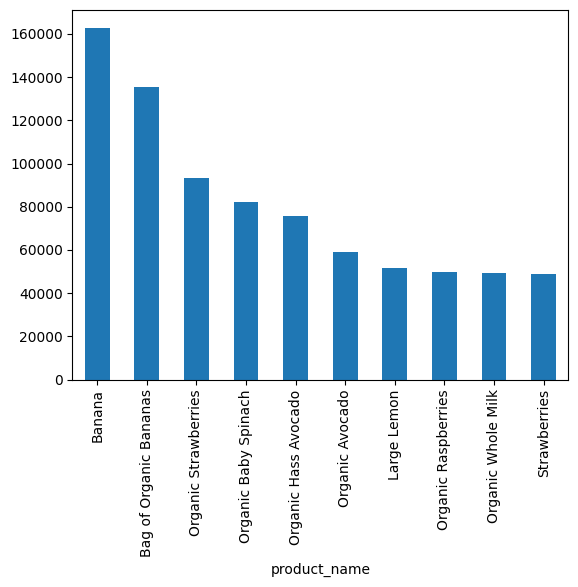

In [25]:
# barplot of the top10 sell products
df["product_name"].value_counts().head(10).plot(kind="bar")

### What is the most sell aisle ?

<Axes: xlabel='aisle'>

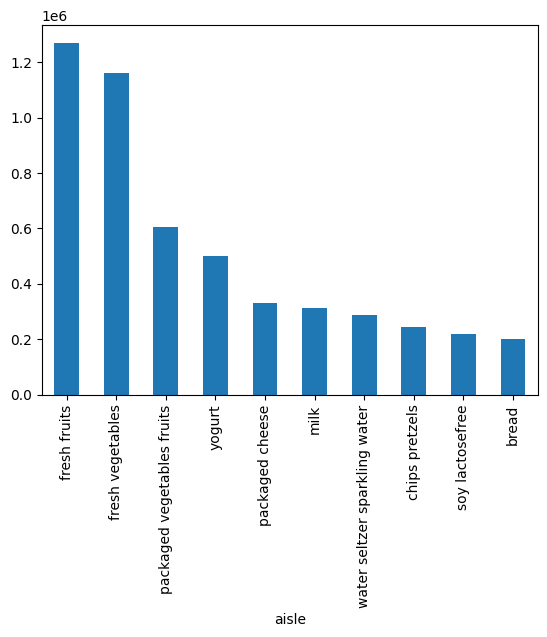

In [26]:
# barplot of the top10 sell aisles
df["aisle"].value_counts().head(10).plot(kind="bar")

### What is the most important client ?

<Axes: xlabel='user_id'>

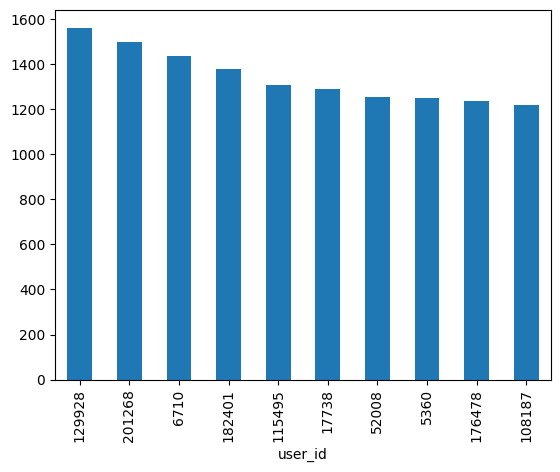

In [27]:
# barplot of the top10 most imporant clients
df["user_id"].value_counts().head(10).plot(kind="bar")

### Which day has the most orders?

<Axes: xlabel='order_dow'>

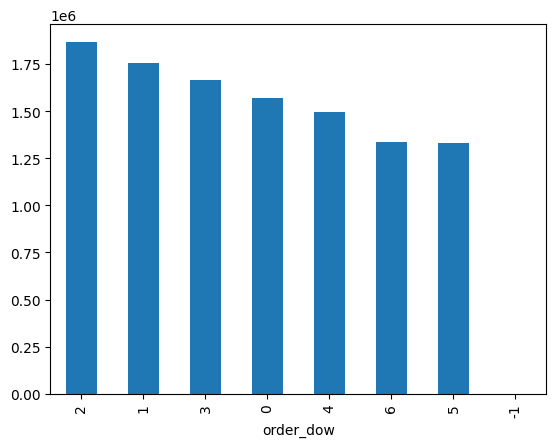

In [28]:
# graph of the number of orders per day
# 0 : Sunday, 1 : Monday, 2 : Tuesday, 3 : Wednesday, 4 : Thursday, 5 : Friday, 6 : Saturday, -1 : Nan/No value
df["order_dow"].value_counts().plot(kind="bar")

### Which hour of day has the most orders?

<Axes: xlabel='order_hour_of_day'>

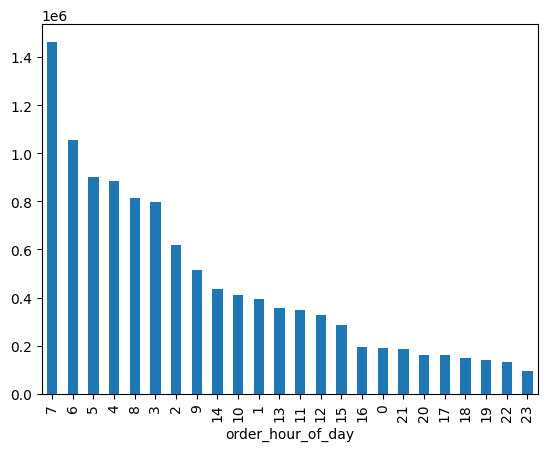

In [29]:
# graph of the number of orders per hour
df["order_hour_of_day"].value_counts().plot(kind="bar")

### When is the busiest time for orders?

In [30]:
# create a new column with day and hour
# format : day-hour
df["order_dow_hour"] = df["order_dow"].astype(str) +"-"+df["order_hour_of_day"].astype(str)

<Axes: xlabel='order_dow_hour'>

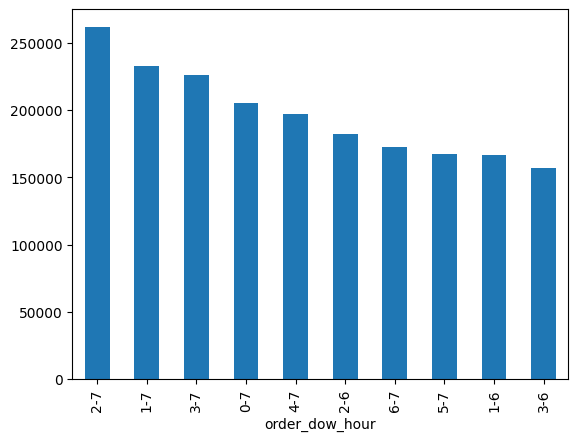

In [31]:
# graph showing the top 10 of the day and the hours with the most orders
# 0 : Sunday, 1 : Monday, 2 : Tuesday, 3 : Wednesday, 4 : Thursday, 5 : Friday, 6 : Saturday, -1 : Nan/No value
df["order_dow_hour"].value_counts().head(10).plot(kind="bar")

In [32]:
def get_user_habit(give_df):
    habit_per_client = {}
    for index,row in give_df.iterrows():
        if index < 10000000000 :
            user_id = row["user_id"]
            order_id = row["order_id"]
            date = row["order_dow_hour"]
            day = row["order_dow"]
            hour = row["order_hour_of_day"]
            product = row["product_name"]
            if user_id not in habit_per_client:
                habit_per_client[user_id] = {
                    "count":0,
                    "day": {0:0,1:0,2:0,3:0,4:0,5:0,6:0,"Nan":0},
                    "hour":{0:0,1:0,2:0,3:0,4:0,5:0,6:0,7:0,8:0,9:0,10:0,11:0,12:0,13:0,14:0,15:0,16:0,17:0,18:0,19:0,20:0,21:0,22:0,23:0,"Nan":0}
                }
                habit_per_client[user_id][order_id] = {
                    "date":date,
                    "content":[product]
                }
                habit_per_client[user_id]["count"] += 1
                if day < 0 : 
                    habit_per_client[user_id]["day"]["Nan"] += 1
                else : 
                    habit_per_client[user_id]["day"][day] += 1
                if hour < 0 :
                    habit_per_client[user_id]["hour"]["Nan"] += 1
                else :
                    habit_per_client[user_id]["hour"][hour] += 1

            else :
                if order_id in habit_per_client[user_id]:
                    habit_per_client[user_id][order_id]["content"].append(product)
                else :
                    habit_per_client[user_id][order_id] = {
                        "date":date,
                        "content":[product]
                    }
                    habit_per_client[user_id]["count"] += 1
                    if day < 0 : 
                        habit_per_client[user_id]["day"]["Nan"] += 1
                    else : 
                        habit_per_client[user_id]["day"][day] += 1
                    if hour < 0 :
                        habit_per_client[user_id]["hour"]["Nan"] += 1
                    else :
                        habit_per_client[user_id]["hour"][hour] += 1


    sorted_habit_per_client = dict(sorted(habit_per_client.items(), key=lambda item: len(item[1]), reverse=True))
    return sorted_habit_per_client

with open('habit.json', 'w') as file:
    json.dump(get_user_habit(df), file, indent=4)
